<a href="https://colab.research.google.com/github/gokulravi123/spam_sms_predict/blob/main/spam_sms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)

uploaded = files.upload()

TensorFlow version: 2.21.0


In [47]:
df = pd.read_csv("spam_sms.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (5572, 2)

Column names:
['v1', 'v2']

First 5 rows:


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [48]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nClass distribution:")
print(df["v1"].value_counts())

print("\nClass distribution percentage:")
print((df["v1"].value_counts(normalize=True) * 100).round(2))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing values:
v1    0
v2    0
dtype: int64

Duplicate rows:
403

Class distribution:
v1
ham     4825
spam     747
Name: count, dtype: int64

Class distribution percentage:
v1
ham     86.59
spam    13.41
Name: proportion, dtype: float64


In [49]:
# Select the required columns
df = df[["v1", "v2"]].copy()

# Rename the columns
df.columns = ["label", "message"]

# Remove missing values
df = df.dropna(subset=["label", "message"])

# Clean the label and message text
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

# Keep valid labels and non-empty messages
df = df[
    df["label"].isin(["ham", "spam"]) &
    df["message"].ne("")
].copy()

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Convert labels to numbers: ham = 0, spam = 1
df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
}).astype("int32")

print("Cleaned dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["label"].value_counts())

display(df.head())

Cleaned dataset shape: (5158, 2)

Missing values:
label      0
message    0
dtype: int64

Class distribution:
label
0    4516
1     642
Name: count, dtype: int64


,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


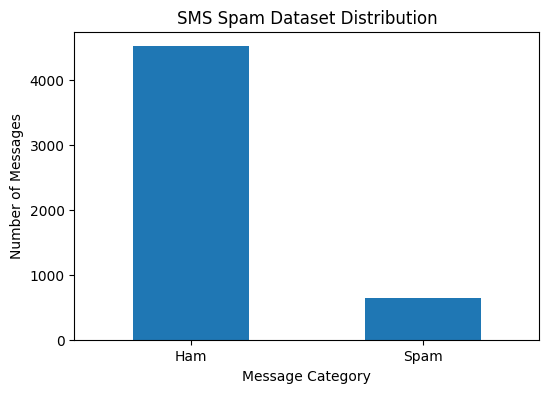

In [50]:
label_counts = df["label"].map({
    0: "Ham",
    1: "Spam"
}).value_counts()

label_counts.plot(kind="bar", rot=0, figsize=(6, 4))

plt.title("SMS Spam Dataset Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.show()

        word_count  character_count
count  5158.000000      5158.000000
mean     15.317759        78.783249
std      11.068793        58.189675
min       1.000000         2.000000
25%       7.000000        36.000000
50%      12.000000        60.000000
75%      22.000000       116.000000
max     171.000000       910.000000


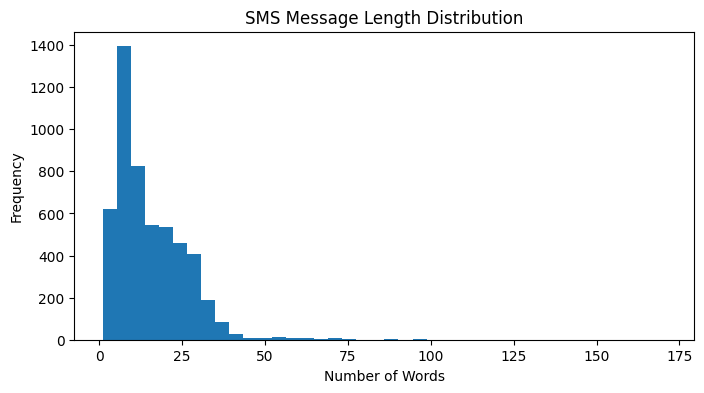

In [51]:
df["word_count"] = df["message"].str.split().str.len()
df["character_count"] = df["message"].str.len()

print(df[["word_count", "character_count"]].describe())

plt.figure(figsize=(8, 4))
plt.hist(df["word_count"], bins=40)
plt.title("SMS Message Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

In [52]:
X = df["message"].values
y = df["label"].values

# Split 15% for testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Split 15% of the total data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=y_train_val
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 3610
Validation samples: 774
Testing samples: 774


In [53]:
from tensorflow.keras.layers import TextVectorization

MAX_TOKENS = 10000
MAX_LENGTH = 50

vectorizer = TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=MAX_LENGTH,
    standardize="lower_and_strip_punctuation",
    split="whitespace"
)

# Learn vocabulary only from training messages
vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(X_train).batch(64)
)

# Convert messages into numerical sequences
X_train_seq = vectorizer(
    tf.constant(X_train)
).numpy()

X_val_seq = vectorizer(
    tf.constant(X_val)
).numpy()

X_test_seq = vectorizer(
    tf.constant(X_test)
).numpy()

vocab_size = len(vectorizer.get_vocabulary())

print("Vocabulary size:", vocab_size)
print("Training sequence shape:", X_train_seq.shape)
print("Validation sequence shape:", X_val_seq.shape)
print("Testing sequence shape:", X_test_seq.shape)

print("\nOriginal SMS:")
print(X_train[0])

print("\nPadded numerical sequence:")
print(X_train_seq[0])

Vocabulary size: 7611
Training sequence shape: (3610, 50)
Validation sequence shape: (774, 50)
Testing sequence shape: (774, 50)

Original SMS:
Orange customer, you may now claim your FREE CAMERA PHONE upgrade for your loyalty. Call now on 0207 153 9996. Offer ends 14thMarch. T&C's apply. Opt-out availa

Padded numerical sequence:
[ 411  256    4  284   23  129   14   50  395  105 2090   13   14 1431
   18   23   19 3011 2981 7109  456 1093 7391  377  398 1745 6855    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]


In [54]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

Class weights: {0: 0.5712025316455697, 1: 4.011111111111111}


In [55]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    GRU,
    Dropout,
    Dense
)

model = Sequential([
    Input(shape=(MAX_LENGTH,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),

    GRU(64),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 64)         │       487,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 512,129 (1.95 MB)

 Trainable params: 512,129 (1.95 MB)

 Non-trainable params: 0 (0.00 B)

In [56]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_seq,
    y_train,
    validation_data=(X_val_seq, y_val),
    epochs=12,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/12
113/113 ━━━━━━━━━━━━━━━━━━━━ 8s 53ms/step - accuracy: 0.8845 - loss: 0.3850 - val_accuracy: 0.9548 - val_loss: 0.1618
Epoch 2/12
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.9881 - loss: 0.0673 - val_accuracy: 0.9806 - val_loss: 0.0744
Epoch 3/12
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.9978 - loss: 0.0182 - val_accuracy: 0.9767 - val_loss: 0.0940
Epoch 4/12
113/113 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.9997 - loss: 0.0046 - val_accuracy: 0.9806 - val_loss: 0.0822
Epoch 5/12
113/113 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step - accuracy: 0.9997 - loss: 0.0020 - val_accuracy: 0.9819 - val_loss: 0.0893


<Figure size 1200x400 with 0 Axes>

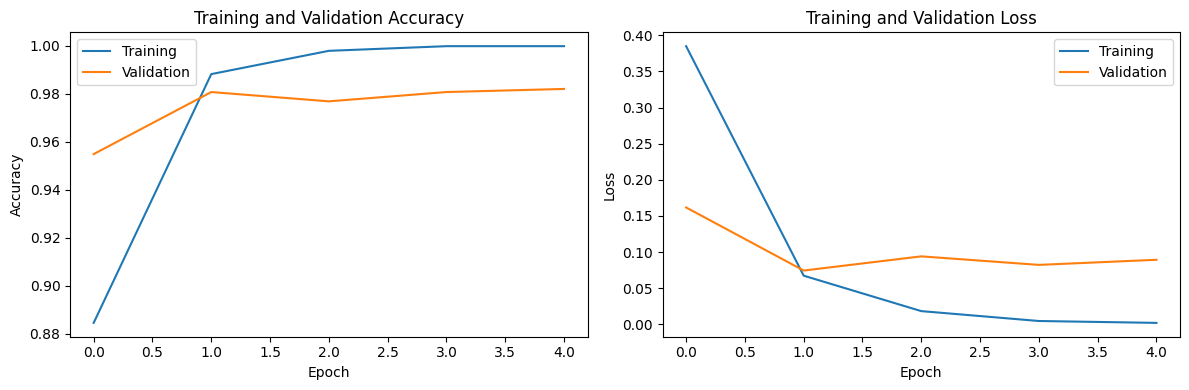

In [59]:
plt.figure(figsize=(12, 4))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [39]:
y_prob = model.predict(X_test_seq, verbose=0).ravel()

y_pred = (y_prob >= 0.5).astype(int)

print("Actual labels:", y_test[:10])
print("Predicted labels:", y_pred[:10])
print("Spam probabilities:", np.round(y_prob[:10], 3))

Actual labels: [0 0 0 0 0 0 0 0 0 0]
Predicted labels: [0 0 0 0 0 0 0 0 0 0]
Spam probabilities: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [61]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Ham", "Spam"],
        digits=4,
        zero_division=0
    )
)

Accuracy:  0.9742 (97.42%)
Precision: 0.9043
Recall:    0.8854
F1-score:  0.8947

Classification Report:
              precision    recall  f1-score   support

         Ham     0.9838    0.9867    0.9853       678
        Spam     0.9043    0.8854    0.8947        96

    accuracy                         0.9742       774
   macro avg     0.9440    0.9361    0.9400       774
weighted avg     0.9740    0.9742    0.9740       774



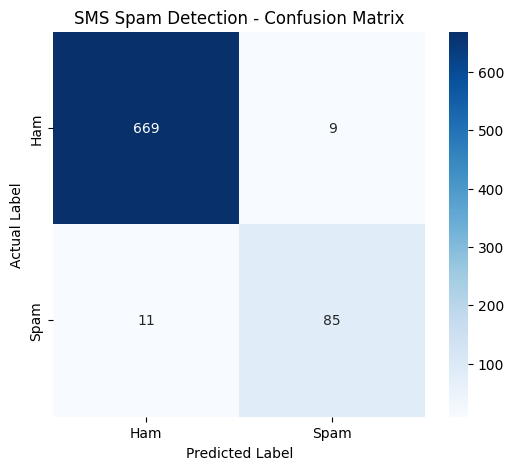

True Negatives: 669
False Positives: 9
False Negatives: 11
True Positives: 85


In [41]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("SMS Spam Detection - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print("True Negatives:", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives:", cm[1, 1])

In [26]:
unseen_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hi, are we meeting at college tomorrow?",
    "URGENT! You have won cash. Reply now to claim.",
    "Please bring your notebook to class.",
    "You have been selected for a free mobile offer.",
    "I will call you when I reach home."
]

# Convert new messages into padded sequences
unseen_sequences = vectorizer(
    tf.constant(unseen_messages)
).numpy()

# Predict probabilities
probabilities = model.predict(
    unseen_sequences,
    verbose=0
).ravel()

# Convert probabilities into labels
predictions = (probabilities >= 0.5).astype(int)

results = pd.DataFrame({
    "SMS Message": unseen_messages,
    "Spam Probability": np.round(probabilities, 4),
    "Prediction": [
        "Spam" if p == 1 else "Ham"
        for p in predictions
    ]
})

display(results)

,SMS Message,Spam Probability,Prediction
0,Congratulations! You have won a free prize. Ca...,0.9996,Spam
1,"Hi, are we meeting at college tomorrow?",0.0000,Ham
2,URGENT! You have won cash. Reply now to claim.,0.9999,Spam
3,Please bring your notebook to class.,0.6873,Spam
4,You have been selected for a free mobile offer.,0.9573,Spam
5,I will call you when I reach home.,0.0000,Ham


In [27]:
def predict_sms(message):
    sequence = vectorizer(
        tf.constant([message])
    ).numpy()

    probability = float(
        model.predict(sequence, verbose=0)[0][0]
    )

    if probability >= 0.5:
        prediction = "Spam"
    else:
        prediction = "Ham"

    print("SMS Message:", message)
    print("Prediction:", prediction)
    print(f"Spam Probability: {probability:.2%}")


predict_sms("Congratulations! You won a cash prize. Claim now.")

SMS Message: Congratulations! You won a cash prize. Claim now.
Prediction: Spam
Spam Probability: 99.99%


In [18]:
model.save("/content/sms_spam_gru.keras")

# Save the fitted vocabulary
vocabulary = vectorizer.get_vocabulary()

with open(
    "/content/sms_vocabulary.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(vocabulary))

print("Model and vocabulary saved.")

Model and vocabulary saved.


In [19]:
from google.colab import files

files.download("/content/sms_spam_gru.keras")
files.download("/content/sms_vocabulary.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
import ipywidgets as widgets
from IPython.display import display, clear_output

def check_sms(text, threshold=0.5):
    p = float(model.predict(
        vectorizer.predict if False else vectorizer(
            [text]
        ).numpy(),
        verbose=0
    )[0][0])

    label = "SPAM 🚨" if p >= threshold else "HAM ✅ (Not Spam)"

    print(f"Message    : {text}")
    print(f"Prediction : {label}")
    print(f"P(spam)    : {p:.3f} | P(ham): {1-p:.3f}")


box = widgets.Textarea(
    placeholder="Type or paste an SMS here...",
    description="SMS:",
    layout=widgets.Layout(width="600px", height="100px")
)

btn = widgets.Button(
    description="Check SMS",
    button_style="primary",
    icon="check"
)

out = widgets.Output()


def on_click(_):
    with out:
        clear_output()
        if box.value.strip():
            check_sms(box.value)
        else:
            print("Please type an SMS message.")


btn.on_click(on_click)

display(box, btn, out)

Textarea(value='', description='SMS:', layout=Layout(height='100px', width='600px'), placeholder='Type or past…

Button(button_style='primary', description='Check SMS', icon='check', style=ButtonStyle())

Output()